In [1]:
import json
from pathlib import Path

import ignite
import kagglehub
import matplotlib.pyplot as plt
import scipy
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from ignite.metrics import FID, InceptionScore
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

device = torch.device("mps")
repo_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()
)
run_dir = repo_root / "hw1" / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=True)

## setup data

In [2]:
kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia",
    output_dir=str(repo_root / "hw1" / "data" / "chest-xray-pneumonia"),
)

'/Users/sriram/ucsd/ECE285DGM/hw1/data/chest-xray-pneumonia'

In [3]:
data_root = repo_root / "hw1/data/chest-xray-pneumonia/chest_xray"

transform = transforms.Compose(
    [
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.5, 0.5, 0.5),
            std=(0.5, 0.5, 0.5),
        ),
    ]
)

train_dataset = datasets.ImageFolder(
    root=data_root / "train",
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
)

## encoder

In [4]:
in_channels = 3
hidden_dims = [32, 64, 128, 256, 512]
latent_dim = 1024

modules = []
for h_dim in hidden_dims:
    modules.append(
        nn.Sequential(
            nn.Conv2d(in_channels, h_dim, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(h_dim),
            nn.LeakyReLU(),
        )
    )
    in_channels = h_dim

encoder = nn.Sequential(*modules)
fc_mu = nn.Linear(hidden_dims[-1] * 4, latent_dim)
fc_var = nn.Linear(hidden_dims[-1] * 4, latent_dim)

## decoder

In [5]:
decoder_input = nn.Linear(latent_dim, hidden_dims[-1] * 4)
modules = []
decoder_dims = list(reversed(hidden_dims))
for i in range(len(decoder_dims) - 1):
    modules.append(
        nn.Sequential(
            nn.ConvTranspose2d(
                decoder_dims[i],
                decoder_dims[i + 1],
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1,
            ),
            nn.BatchNorm2d(decoder_dims[i + 1]),
            nn.LeakyReLU(),
        )
    )
modules.append(
    nn.Sequential(
        nn.ConvTranspose2d(
            decoder_dims[-1],
            3,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1,
        ),
        nn.Tanh(),
    )
)

decoder = nn.Sequential(*modules)

## VAE

In [6]:
class VAE(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.encoder = encoder
        self.fc_mu = fc_mu
        self.fc_var = fc_var
        self.decoder_input = decoder_input
        self.decoder = decoder

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        latent = self.encoder(x)
        latent = torch.flatten(latent, start_dim=1)
        mu = self.fc_mu(latent)
        log_var = self.fc_var(latent)
        return (mu, log_var)

    def sample_and_decode(
        self, mu: torch.Tensor, log_var: torch.Tensor
    ) -> torch.Tensor:
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        z = mu + eps * std
        reconstructed = self.decoder_input(z)
        reconstructed = reconstructed.view(z.size(0), -1, 2, 2)
        reconstructed = self.decoder(reconstructed)
        return reconstructed

    def forward(
        self, x: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        mu, log_var = self.encode(x)
        reconstructed = self.sample_and_decode(mu, log_var)
        return reconstructed, mu, log_var

    def loss(
        self,
        x: torch.Tensor,
        reconstructed_x: torch.Tensor,
        mu: torch.Tensor,
        log_var: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        reconstruction_loss = F.mse_loss(reconstructed_x, x)
        kld_loss = torch.mean(
            -0.5 * torch.sum(1 + log_var - mu**2 - log_var.exp(), dim=1), dim=0
        )
        return (reconstruction_loss, kld_loss)

In [7]:
model = VAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Train

In [8]:
class LossHistory:
    def __init__(self) -> None:
        self.reconstruction_losses: list[float] = []
        self.kld_losses: list[float] = []
        self.total_losses: list[float] = []

    def to_dict(self) -> dict[str, list[float]]:
        return {
            "reconstruction_losses": self.reconstruction_losses,
            "kld_losses": self.kld_losses,
            "total_losses": self.total_losses,
        }


loss_history = LossHistory()
num_epochs = 30
kl_weight = 0.001

In [9]:
start_epoch = len(loss_history.total_losses)
for epoch in range(start_epoch, start_epoch + num_epochs):
    model.train()
    epoch_reconstruction = 0.0
    epoch_kld = 0.0
    epoch_total = 0.0
    num_images = 0

    for images, _ in train_loader:
        images = images.to(device)
        batch_size = images.size(0)
        optimizer.zero_grad()

        reconstruction, mu, log_var = model(images)
        reconstruction_loss, kld_loss = model.loss(images, reconstruction, mu, log_var)
        loss = reconstruction_loss + kl_weight * kld_loss

        loss.backward()
        optimizer.step()

        epoch_reconstruction += reconstruction_loss.item() * batch_size
        epoch_kld += kld_loss.item() * batch_size
        epoch_total += loss.item() * batch_size
        num_images += batch_size

    loss_history.reconstruction_losses.append(epoch_reconstruction / num_images)
    loss_history.kld_losses.append(epoch_kld / num_images)
    loss_history.total_losses.append(epoch_total / num_images)

    torch.save(
        {
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": loss_history.to_dict(),
            "kl_weight": kl_weight,
        },
        run_dir / "checkpoint.pt",
    )
    with (run_dir / "loss_history.json").open("w") as f:
        json.dump(loss_history.to_dict(), f, indent=2)

    print(
        f"Epoch {epoch + 1}: "
        f"total={loss_history.total_losses[-1]:.6f}, "
        f"reconstruction={loss_history.reconstruction_losses[-1]:.6f}, "
        f"KL={loss_history.kld_losses[-1]:.6f}"
    )

Epoch 1: total=0.125663, reconstruction=0.103249, KL=22.414609
Epoch 2: total=0.071434, reconstruction=0.057804, KL=13.630558
Epoch 3: total=0.065110, reconstruction=0.052439, KL=12.671371
Epoch 4: total=0.060957, reconstruction=0.049374, KL=11.583477
Epoch 5: total=0.058386, reconstruction=0.047090, KL=11.295784
Epoch 6: total=0.057165, reconstruction=0.046227, KL=10.938755
Epoch 7: total=0.055488, reconstruction=0.044621, KL=10.867382
Epoch 8: total=0.054792, reconstruction=0.044010, KL=10.782202
Epoch 9: total=0.054474, reconstruction=0.043548, KL=10.926561
Epoch 10: total=0.053652, reconstruction=0.042847, KL=10.805169
Epoch 11: total=0.053781, reconstruction=0.042793, KL=10.987428
Epoch 12: total=0.053367, reconstruction=0.042149, KL=11.217959
Epoch 13: total=0.052929, reconstruction=0.041864, KL=11.065410
Epoch 14: total=0.052586, reconstruction=0.041482, KL=11.103413
Epoch 15: total=0.052194, reconstruction=0.041018, KL=11.176616
Epoch 16: total=0.052115, reconstruction=0.040825

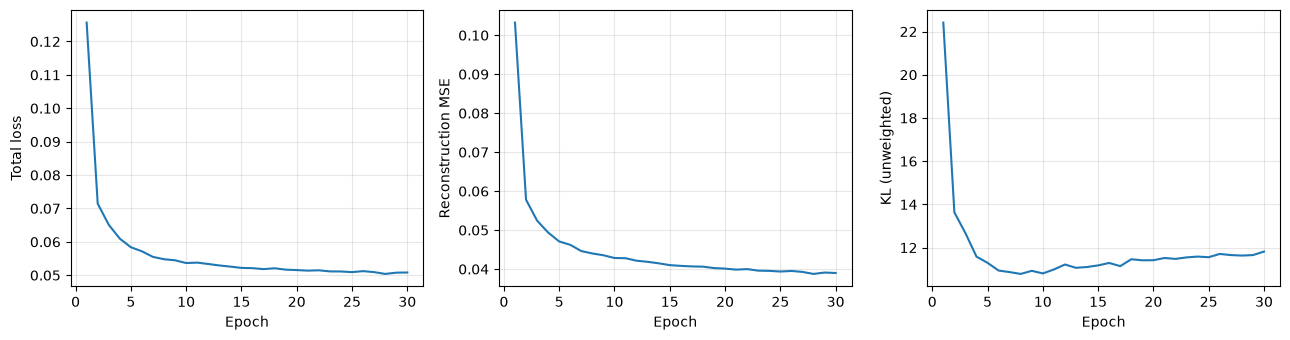

In [10]:
epochs = range(1, len(loss_history.total_losses) + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, values, title in zip(
    axes,
    [
        loss_history.total_losses,
        loss_history.reconstruction_losses,
        loss_history.kld_losses,
    ],
    ["Total loss", "Reconstruction MSE", "KL (unweighted)"],
):
    ax.plot(epochs, values)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "training_losses.png", dpi=300)
plt.show()

In [11]:
# checkpoint = torch.load(
#     run_dir / "checkpoint.pt", map_location="cpu", weights_only=True
# )
# model.load_state_dict(checkpoint["model"])
# optimizer.load_state_dict(checkpoint["optimizer"])
# loss_history = LossHistory()
# loss_history.reconstruction_losses = checkpoint["history"]["reconstruction_losses"]
# loss_history.kld_losses = checkpoint["history"]["kld_losses"]
# loss_history.total_losses = checkpoint["history"]["total_losses"]
# kl_weight = checkpoint["kl_weight"]

## Eval


In [12]:
eval_batch_size = 16
eval_seed = 42

model.eval()
model_device = next(model.parameters()).device

eval_dataset = datasets.ImageFolder(
    data_root / "test",
    transform=transform,
)
eval_loader = DataLoader(
    eval_dataset, batch_size=eval_batch_size, shuffle=False, drop_last=False
)

In [13]:
metric_rng = torch.Generator(device="cpu").manual_seed(eval_seed)
fid_metric = FID(device="cpu")
is_metric = InceptionScore(device="cpu")
fid_metric.reset()
is_metric.reset()
model.eval()

with torch.inference_mode():
    for real_images, _ in eval_loader:
        z = torch.randn(
            real_images.size(0), model.fc_mu.out_features, generator=metric_rng
        ).to(model_device)
        features = model.decoder_input(z).view(z.size(0), -1, 2, 2)
        fake_images = model.decoder(features)

        metric_batches = []
        for images in (fake_images, real_images):
            images = ((images.detach().cpu() + 1) / 2).clamp(0, 1)
            resized = []
            for image in images:
                pil_image = transforms.functional.to_pil_image(image)
                pil_image = pil_image.resize((299, 299), Image.Resampling.BILINEAR)
                resized.append(transforms.functional.to_tensor(pil_image))
            metric_batches.append(torch.stack(resized))

        fake, real = metric_batches
        fid_metric.update((fake, real))
        is_metric.update(fake)

results = {
    "fid": float(fid_metric.compute()),
    "inception_score": float(is_metric.compute()),
}
with (run_dir / "metrics.json").open("w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "fid": 0.15199728633668902,
  "inception_score": 1.2862199082806423
}


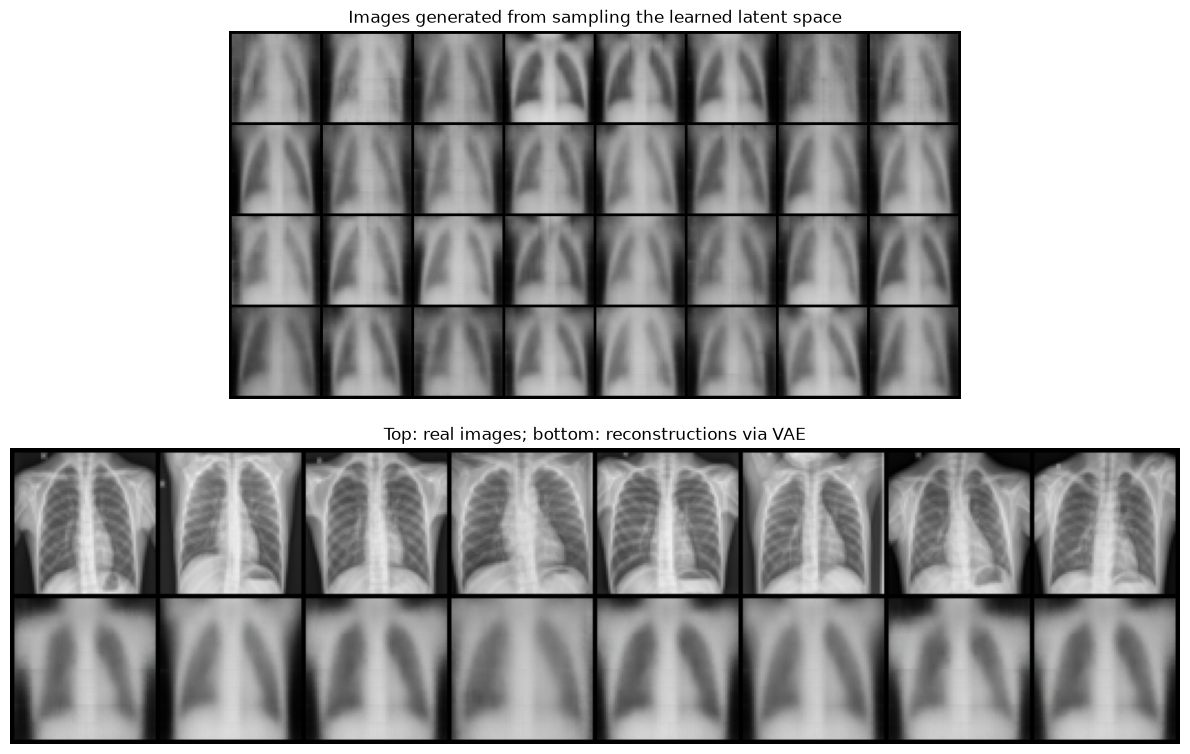

In [14]:
figure_rng = torch.Generator(device="cpu").manual_seed(eval_seed)
model.eval()
with torch.inference_mode():
    sample_z = torch.randn(32, model.fc_mu.out_features, generator=figure_rng).to(
        model_device
    )
    features = model.decoder_input(sample_z).view(sample_z.size(0), -1, 2, 2)
    samples = ((model.decoder(features).cpu() + 1) / 2).clamp(0, 1)

    real_examples = next(iter(eval_loader))[0][:8]
    mu, _ = model.encode(real_examples.to(model_device))
    features = model.decoder_input(mu).view(mu.size(0), -1, 2, 2)
    reconstructions = ((model.decoder(features).cpu() + 1) / 2).clamp(0, 1)
    real_examples = ((real_examples + 1) / 2).clamp(0, 1)

sample_grid = make_grid(samples, nrow=8, padding=2)
comparison_grid = make_grid(
    torch.cat([real_examples, reconstructions]),
    nrow=real_examples.size(0),
    padding=2,
)
save_image(sample_grid, run_dir / "generated_samples.png")
save_image(comparison_grid, run_dir / "reconstructions.png")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].imshow(sample_grid.permute(1, 2, 0).numpy())
axes[0].set_title("Images generated from sampling the learned latent space")
axes[1].imshow(comparison_grid.permute(1, 2, 0).numpy())
axes[1].set_title("Top: real images; bottom: reconstructions via VAE")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(run_dir / "report_samples.png", dpi=300)
plt.show()